# When should an assistant think harder? Evaluating a per-turn reasoning router

Zephyro (my personal assistant) can answer each message with the model's
reasoning **on** (slower, better on hard problems) or **off** (fast). A
hand-written regex router (`backend/core/reasoning_policy.py`, ~0.05 ms per
message) picks a level per message: `low` / `medium` / `high`. On DeepSeek only
`high` turns thinking on.

Questions this notebook answers, with uncertainty attached:

1. **Are the labels themselves reliable?** (they cap every router's score)
2. **Does the regex router generalize** to prompts it was not designed on, and does a learned model do better?
3. **Does thinking actually improve answers**, and what does it cost in latency?
4. **Can an LLM judge measure the difference?**

The errors are not symmetric. Routing a hard prompt to `low` gives a wrong
answer fast. Routing an easy one to `high` gives a right answer about 1 s later. So
next to accuracy I track the **under-routing rate** and the **recall on `high`**.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score, confusion_matrix, f1_score

from reasoning_eval.data import LEVELS, ROOT, heuristic, load_prompts, load_runs
from reasoning_eval import metrics as M
from reasoning_eval.models import MajorityRouter, loocv_predictions, tfidf_logreg

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

prompts = load_prompts()
runs = load_runs()
pick = heuristic()
prompts["regex"] = [pick(t).level for t in prompts["prompt"]]
dev, holdout = prompts[prompts.split == "dev"], prompts[prompts.split == "holdout"]

## 1. Data

| split | written by | used for |
|---|---|---|
| **dev** (40) | me | designing the regex rules: **in-sample** for the regex |
| **holdout** (24) | Codex (a different model family), sealed until the final test | the only fair test of generalization |

The regex was **not** changed after the holdout was opened, so it is still a clean test.

In [2]:
pd.crosstab(prompts.split, prompts.expected_level, margins=True)

expected_level,low,medium,high,All
split,,,,
dev,13,13,14,40
holdout,6,8,10,24
All,19,21,24,64


## 2. How reliable are the labels?

A second annotator (DeepSeek V4 Pro) labeled all 64 prompts **blind**: it saw
only the rubric and the prompt (`scripts/label_with_llm.py`). Linear-weighted Cohen's κ
treats `low`↔`high` as a worse disagreement than `low`↔`medium`.

In [3]:
rows = []
for name, df in [("dev", dev), ("holdout", holdout), ("all", prompts)]:
    y, z = df.expected_level.astype(str), df.llm_level
    rows.append({"split": name, "n": len(df), "agreement": (y == z).mean(),
                 "kappa_linear": cohen_kappa_score(y, z, weights="linear", labels=LEVELS)})
agreement = pd.DataFrame(rows).set_index("split")
agreement

,n,agreement,kappa_linear
split,,,
dev,40,0.700,0.662
holdout,24,0.792,0.760
all,64,0.734,0.699


In [4]:
pd.crosstab(prompts.expected_level, prompts.llm_level, rownames=["reference label"], colnames=["blind LLM label"])

blind LLM label,high,low,medium
reference label,,,
low,0,13,6
medium,10,0,11
high,23,0,1


**Reading.** Agreement is substantial but far from perfect: κ ≈ 0.70 overall,
lower on my dev labels than on the holdout. The disagreements are **not** where I
expected them. 10 of the 17 are prompts I labeled `medium` that the blind labeler
calls `high`, and that is the one boundary that changes the DeepSeek decision
(thinking on or off). The blind labeler is systematically more willing to think
than I am.

**Consequence:** a 3-class accuracy around 0.7–0.8 is about what these labels can
support. And "which `medium` prompts deserve thinking" is a genuinely ambiguous
question, not a router bug. *(Pitfall worth noting: `cohen_kappa_score` with
`weights="linear"` needs `labels=LEVELS`. Without it, sklearn orders the classes
alphabetically (`high, low, medium`), the ordinal weights become wrong, and my first
quick run reported κ = 0.53.)*

## 3. Does the router generalize?

Four routers, all scored on the **holdout**:

- **majority**: always the most frequent dev label (`high`). It is the floor, and it
  is trivially perfect on recall: it always thinks.
- **regex**: the production heuristic.
- **TF-IDF + logistic regression**: character 2–5-grams, trained on the 40 dev prompts.
- **blind LLM labeler**: what a much more expensive router (an LLM call per message) would decide.

Intervals are 95% percentile bootstrap over prompts (5,000 resamples).

In [5]:
y_dev = dev.expected_level.astype(str).values
y_ho = holdout.expected_level.astype(str).values
lr = tfidf_logreg(1.0).fit(list(dev.prompt), y_dev)
routers = {
    "majority": MajorityRouter().fit(dev.prompt, y_dev).predict(list(holdout.prompt)),
    "regex": holdout.regex.values,
    "tfidf_logreg": lr.predict(list(holdout.prompt)),
    "llm_labeler": holdout.llm_level.values,
}
accuracy = lambda t, p: float(np.mean(t == p))
metric_fns = {"accuracy": accuracy, "under_rate": M.under_rate, "high_recall": M.high_recall}
rows = []
for name, pred in routers.items():
    for metric, fn in metric_fns.items():
        point, lo, hi = M.bootstrap_ci(y_ho, pred, fn)
        rows.append({"router": name, "metric": metric, "value": point, "ci_low": lo, "ci_high": hi})
holdout_scores = pd.DataFrame(rows)
holdout_scores.pivot(index="router", columns="metric", values="value").loc[list(routers)]

metric,accuracy,high_recall,under_rate
router,,,
majority,0.417,1.0,0.000
regex,0.667,0.8,0.167
tfidf_logreg,0.708,1.0,0.000
llm_labeler,0.792,1.0,0.000


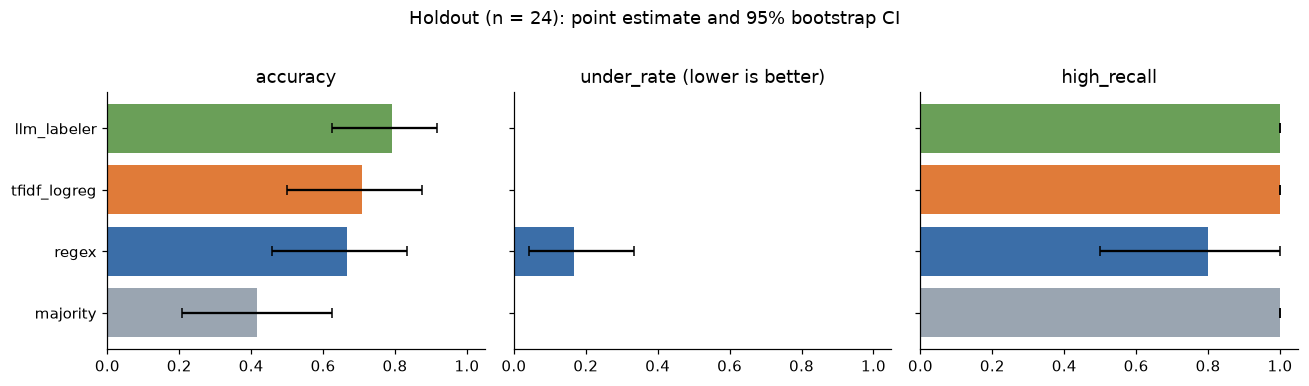

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
names = list(routers)
for ax, metric in zip(axes, metric_fns):
    d = holdout_scores[holdout_scores.metric == metric].set_index("router").loc[names]
    err = np.vstack([d.value - d.ci_low, d.ci_high - d.value])
    ax.barh(names, d.value, xerr=err, color=["#9aa5b1", "#3b6ea8", "#e07b39", "#6a9f58"], capsize=3)
    ax.set_title(metric + (" (lower is better)" if metric == "under_rate" else ""))
    ax.set_xlim(0, 1.05)
fig.suptitle("Holdout (n = 24): point estimate and 95% bootstrap CI", y=1.02)
fig.tight_layout()
fig.savefig(FIG / "holdout_routers.png", bbox_inches="tight")

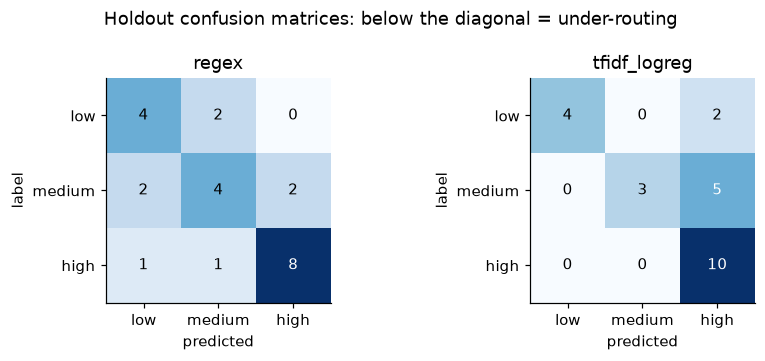

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.3))
for ax, name in zip(axes, ["regex", "tfidf_logreg"]):
    cm = confusion_matrix(y_ho, routers[name], labels=LEVELS)
    ax.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 4 else "black")
    ax.set_xticks(range(3), LEVELS); ax.set_yticks(range(3), LEVELS)
    ax.set_xlabel("predicted"); ax.set_ylabel("label"); ax.set_title(name)
fig.suptitle("Holdout confusion matrices: below the diagonal = under-routing")
fig.tight_layout()
fig.savefig(FIG / "confusion.png", bbox_inches="tight")

In [8]:
# Inside dev the learned model can only be scored by cross-validation; the regex
# number on dev is in-sample (the rules were written while looking at these prompts).
loo = loocv_predictions(dev.prompt, y_dev)
pd.DataFrame({
    "regex (in-sample)": [accuracy(y_dev, dev.regex.values), M.under_rate(y_dev, dev.regex.values)],
    "tfidf_logreg (LOOCV)": [accuracy(y_dev, loo), M.under_rate(y_dev, loo)],
}, index=["accuracy", "under_rate"])

,regex (in-sample),tfidf_logreg (LOOCV)
accuracy,0.875,0.525
under_rate,0.000,0.125


**Reading.**

- **On its own design set the regex looks perfect, and that number is meaningless.**
  The rules were written to fit those prompts. On the holdout it is the only router
  that under-routes: 4 of 24 prompts. Two of those are `medium`→`low`, harmless on
  DeepSeek. Two are hard prompts left without thinking: a date-arithmetic prompt with
  the number spelled out ("noventa días") went to `low`, and a constrained ordering
  puzzle went to `medium`.
- **The learned model is not clearly better.** With 24 test prompts every 95% interval
  is about ±0.2 wide and the intervals overlap. Its holdout errors are all
  over-routing, but under LOOCV on dev it scores only 0.53 and under-routes 12% of
  prompts. The honest conclusion is **"no detectable difference at this sample size"**,
  not "ML wins".
- **The ceiling is the label noise from section 2**, not the model.

## 4. Does thinking improve the answers?

Verifiable prompts (math, logic and code, checked by regex or by running unit
tests) under three configs: `off` (today), `low` (thinking always on) and `policy`
(thinking on only where the router says `high`). Every config ran each prompt twice.

The effect is estimated **per prompt** (each prompt's mean over its repeats),
and intervals come from a **cluster bootstrap over prompts**. Resampling individual
runs would count two correlated runs of the same prompt as independent evidence.

In [9]:
ver = runs[runs["pass"].notna()].copy()
ver["pass"] = ver["pass"].astype(bool)
pass_rates = (ver.groupby(["id", "cfg"])["pass"].mean().unstack("cfg").mean()
              .rename("pass_rate (mean over prompts)").to_frame())
pass_rates["prompts"] = ver.groupby("cfg").id.nunique()
pass_rates

,pass_rate (mean over prompts),prompts
cfg,,
deepseek:low,0.968,31
deepseek:off,0.935,31
deepseek:policy,0.968,31


In [10]:
rows = []
for a, b in [("deepseek:low", "deepseek:off"), ("deepseek:policy", "deepseek:off"), ("deepseek:low", "deepseek:policy")]:
    point, lo, hi = M.cluster_bootstrap_diff(ver, a, b)
    mc = M.mcnemar_exact(ver, a, b)
    rows.append({"comparison": f"{a.split(':')[1]} - {b.split(':')[1]}", "pass_rate_diff": point,
                 "ci_low": lo, "ci_high": hi, "discordant_prompts": mc["discordant"], "mcnemar_p": mc["p_value"]})
pd.DataFrame(rows).set_index("comparison")

,pass_rate_diff,ci_low,ci_high,discordant_prompts,mcnemar_p
comparison,,,,,
low - off,0.032,-0.032,0.097,3,1.0
policy - off,0.032,-0.032,0.097,3,1.0
low - policy,0.000,0.000,0.000,0,1.0


**Reading.** Thinking on: 96.8% of verifiable prompts solved. Thinking off: 93.5%.
The +3.2 pp difference has a 95% CI of [−3.2, +9.7] pp and rests on only 3
discordant prompts (exact McNemar p = 1.0). **It is not distinguishable from zero.**
DeepSeek already solves almost every verifiable prompt with thinking off.
`policy` matches always-on exactly: on these prompts the router turned thinking
on wherever it mattered.

In [11]:
# Which prompts does thinking rescue (or break)?
per_prompt = ver.groupby(["id", "cfg"])["pass"].mean().unstack("cfg")
changed = per_prompt[(per_prompt.nunique(axis=1) > 1)]
changed.join(prompts.set_index("id")[["category", "expected_level", "regex"]])

,deepseek:low,deepseek:off,deepseek:policy,category,expected_level,regex
id,,,,,,
h03,1.0,0.5,1.0,math,high,high
x10,1.0,0.5,1.0,math,medium,high
x16,0.5,0.0,0.5,math,high,high
x17,0.5,1.0,0.5,math,high,high


`h03` (a weekday computed from a date) and `x10` (clock arithmetic) are the real rescues.
`x10` is labeled `medium`, so the router *over*-routed it, and that is what saved it.
`x16` and `x17` are **scorer artifacts**, not reasoning errors: the answers
"1000 pesos" and "288 minutos" are correct, but the holdout's regex demands the
bare number. Strict scorers make results reproducible, and they also put a floor
of false failures under every config.

## 5. What does thinking cost?

Time to first token (TTFT) is what the user feels in a chat, and in voice mode it
decides whether the assistant sounds alive. Below: the distribution over every
run, then the per-prompt median difference with a cluster bootstrap CI.

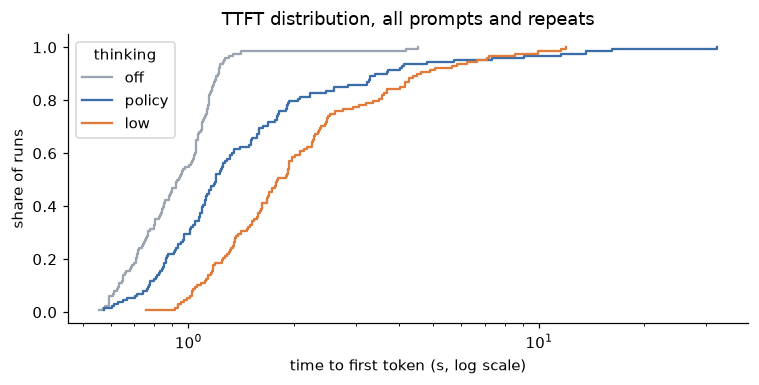

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for cfg, color in [("deepseek:off", "#9aa5b1"), ("deepseek:policy", "#3b6ea8"), ("deepseek:low", "#e07b39")]:
    x = np.sort(runs.loc[runs.cfg == cfg, "ttft"].dropna().to_numpy())
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", label=cfg.split(":")[1], color=color)
ax.set_xscale("log"); ax.set_xlabel("time to first token (s, log scale)"); ax.set_ylabel("share of runs")
ax.legend(title="thinking"); ax.set_title("TTFT distribution, all prompts and repeats")
fig.tight_layout()
fig.savefig(FIG / "ttft_ecdf.png", bbox_inches="tight")

In [13]:
summary = runs.groupby("cfg")["ttft"].describe(percentiles=[0.5, 0.9])[["count", "50%", "90%"]]
rows = []
for a in ["deepseek:policy", "deepseek:low"]:
    point, lo, hi = M.cluster_bootstrap_diff(runs, a, "deepseek:off", value="ttft")
    rows.append({"cfg": a, "mean_ttft_increase_s": point, "ci_low": lo, "ci_high": hi})
summary.join(pd.DataFrame(rows).set_index("cfg"))

,count,50%,90%,mean_ttft_increase_s,ci_low,ci_high
cfg,,,,,,
deepseek:low,128.0,1.799,4.533,1.521,1.091,2.018
deepseek:off,128.0,0.934,1.217,NaN,NaN,NaN
deepseek:policy,128.0,1.196,3.497,1.151,0.496,2.058


**Reading.** Always-on thinking roughly doubles the median TTFT (0.93 s → 1.80 s).
The router keeps the median close to today's (1.20 s), but its tail is long:
p90 is 3.5 s, because the prompts it routes to `high` are the ones where
thinking is longest. Counted per prompt, the mean increase is +1.15 s for the router vs
+1.52 s for always-on, and the two CIs overlap. **The router mostly saves latency on
typical messages, not on the worst case.**

## 6. Can an LLM judge see the difference?

The open-ended prompts (chat, explanations, plans) have no checkable answer. A
judge model compared each answer with the `off` answer, blind and in both orders.

There is a built-in control: on prompts where the router chose `off`, the
`policy` answer and the reference answer come from **the same configuration**. Any
verdict other than "tie" there is **pure noise**: sampling at temperature 0.7 plus
the judge's own variance.

In [14]:
judged = runs[runs["judge"].notna() & runs["judge"].ne("invalid")].copy()
judged["identical_config"] = judged.level.eq("off")
noise = (judged.groupby(["cfg", "identical_config"]).judge.value_counts(normalize=True)
         .unstack().fillna(0)[["worse", "tie", "better"]])
noise["n"] = judged.groupby(["cfg", "identical_config"]).size()
noise

judge                             worse    tie  better   n
cfg             identical_config                          
deepseek:low    False             0.108  0.708   0.185  65
deepseek:policy False             0.000  0.500   0.500   8
                True              0.158  0.807   0.035  57

**Reading.** When `policy` and the reference are literally the same configuration
(n = 57), the judge still returns a non-tie verdict in about 19% of cases:
16% "worse" and 3.5% "better". That is the **noise floor**. The always-on comparison
(11% worse, 18% better, n = 65) sits inside it, so this judge cannot tell whether
thinking improves open-ended answers.

My original acceptance criterion ("the judge says *worse* at most 10% of the time")
was already **below the noise floor**: identical configurations fail it. I would not have
known without this control. (The worse/better asymmetry, 9 vs 2 verdicts, is
compatible with chance at this n. More judged prompts would be needed to call it a bias.)

## 7. Conclusions

1. **Labels are the bottleneck.** Agreement with a blind annotator is substantial (κ ≈ 0.70),
   but the disagreements fall on `medium` vs `high`: exactly the "think or not" decision.
   For this product the router should be a **binary classifier**, evaluated on `high` recall,
   with labels from several adjudicated annotators.
2. **The regex router generalizes imperfectly.** It is perfect on its own design set and
   under-routes 2 of 10 hard holdout prompts. A small learned model does not beat it
   detectably at n = 24.
3. **Thinking has a clear latency cost and no measurable accuracy benefit here.** +3 pp, with a
   CI that crosses zero: DeepSeek already solves almost every verifiable prompt with thinking
   off. The router matches always-on accuracy and keeps the *median* latency close to today's.
   The tail stays long.
4. **Measure the noise floor before trusting an LLM judge.** The identical-configuration control
   shows about 19% non-tie verdicts with no real difference at all, so a "≤ 10% worse" criterion
   was unattainable from the start.

**With more time:** grow the labeled set (several annotators, adjudicated), turn the router into a
calibrated binary classifier that thinks when P(high) > t, with t chosen from the latency-vs-recall
curve, and replace the pairwise judge with more prompts and repeated judging until its noise
floor is below the effect worth detecting.